# Random catalogs

A random catalog belongs to one data catalog. Its points are uniform inside the footprint of the lightcone (the 80 sky
patches, 2578 deg²), and its redshifts are drawn, with replacement, from the data's own. `make_random` takes the data
catalog and nothing else, so any catalog works: a whole contaminated catalog, or a part of it such as its multi-line
galaxies or one kind of interloper.

```python
cat.make_random(10)                                    # 10 times as many points as the data
cat.subset("OIII_5007_as_Ha").make_random(10)          # the randoms of one kind of interloper
cat[cat["redshift_assigned"] < 1.1].make_random(10)    # of any selection
```

`cat.subset(which)` takes the parts of a contaminated catalog by identification outcome:

| `which` | the part | `id_outcome` |
|---|---|---|
| `"all"` | the whole catalog: multi-line galaxies, single-line galaxies with a correct redshift and interlopers | 1, 2, 3 |
| `"multi_line"` | the multi-line galaxies | 1 |
| `"single_correct"` | the single-line galaxies with a correct redshift | 2 |
| `"galaxies"` | every galaxy with a correct redshift (the two above) | 1, 2 |
| `"interlopers"` | every interloper: a single line taken for another line | 3 |
| `"OIII_5007_as_Ha"` | one kind of interloper: [O III] λ5007 single lines taken for Hα | 3, with `line_true`, `line_assigned` |

Any `"<true line>_as_<assigned line>"` works, and `cat.components()` lists the parts present with their sizes. The
randoms of a data catalog depend on the seed and on the data only:

* the same data give the same randoms;
* more points (a larger `n_times`) keep the first ones;
* two different data catalogs, such as two parts of one catalog, get independent randoms with the same seed.

This notebook makes them for the Hα catalog at 1.0 < z < 1.2 that notebook 01 built with the line mix of the mock, so
run notebook 01 first. It runs on a login node in about a minute (`sbatch scripts/run_notebook.sh` works too).

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # romanmock imports diffsky, which imports JAX; keep it off the GPU

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from romanmock import BaseCatalog, Catalog, plotting
from romanmock.plotting import OUTCOME_COLORS, TEXT_PRIMARY, feature_color

plotting.use_style()
OUT = Path(os.environ["PSCRATCH"]) / "RomanMocks" / "examples"
CATALOG = OUT / "Ha_z1p0_1p2_empirical" / "Ha_z1p0_1p2.hdf5"          # the catalog of notebook 01
RANDOMS = OUT / "Ha_z1p0_1p2_empirical" / "randoms"                   # -> Ha_z1p0_1p2_<which>_random.hdf5
N_TIMES, SEED = 2, 2026          # random points per data galaxy; use 10 or more for clustering

cat = Catalog.read(CATALOG)
print(cat)
for which, n in cat.components().items():
    print(f"  {which:<20s}{n:>12,}")


<Catalog: 14,965,874 galaxies, 10 columns ['gal_id', 'ra', 'dec', 'redshift_true', 'redshift_rsd', 'redshift_assigned', 'id_outcome', 'line_true', 'line_assigned', 'n_det']; F > 1.50e-16 (other lines > 6.00e-17); lines ['Ha'], redshift_assigned in (1.0, 1.2), lines rescaled (galacticus_like), doublet per_galaxy>
  all                   14,965,874
  multi_line            14,845,961
  single_correct            81,174
  galaxies              14,927,135
  interlopers               38,739
  SIII_9532_as_Ha           19,445
  OIII_5007_as_Ha           19,294


## The randoms of the whole catalog

`write_to` writes the random catalog to one file, block by block, so a large one never sits in memory at once.
Without `write_to` it is returned as a `Catalog`.

In [2]:
files = {"all": cat.make_random(N_TIMES, seed=SEED, write_to=RANDOMS / "Ha_z1p0_1p2_all_random.hdf5")}


[romanmock] random catalog: 2 x 14,965,874 points, uniform inside 2578.3 deg², redshift_assigned drawn from the data


[romanmock] wrote /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_empirical/randoms/Ha_z1p0_1p2_all_random.hdf5


## The randoms of each part

These are multi-line galaxies only, single-line galaxies with a correct redshift only, every interloper, and each kind of
interloper on its own: here [O III] λ5007 and [S III] λ9532 single lines taken for Hα. Each part is selected with
`subset` and is then a data catalog like any other.

In [3]:
PARTS = ["multi_line", "single_correct", "interlopers", "OIII_5007_as_Ha", "SIII_9532_as_Ha"]
for which in PARTS:
    files[which] = cat.subset(which).make_random(N_TIMES, seed=SEED, write_to=RANDOMS / f"Ha_z1p0_1p2_{which}_random.hdf5")


[romanmock] random catalog: 2 x 14,845,961 points, uniform inside 2578.3 deg², redshift_assigned drawn from the data


[romanmock] wrote /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_empirical/randoms/Ha_z1p0_1p2_multi_line_random.hdf5


[romanmock] random catalog: 2 x 81,174 points, uniform inside 2578.3 deg², redshift_assigned drawn from the data


[romanmock] wrote /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_empirical/randoms/Ha_z1p0_1p2_single_correct_random.hdf5


[romanmock] random catalog: 2 x 38,739 points, uniform inside 2578.3 deg², redshift_assigned drawn from the data


[romanmock] wrote /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_empirical/randoms/Ha_z1p0_1p2_interlopers_random.hdf5


[romanmock] random catalog: 2 x 19,294 points, uniform inside 2578.3 deg², redshift_assigned drawn from the data


[romanmock] wrote /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_empirical/randoms/Ha_z1p0_1p2_OIII_5007_as_Ha_random.hdf5


[romanmock] random catalog: 2 x 19,445 points, uniform inside 2578.3 deg², redshift_assigned drawn from the data


[romanmock] wrote /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_empirical/randoms/Ha_z1p0_1p2_SIII_9532_as_Ha_random.hdf5


## Checks

Every random point should be inside the footprint, and each random catalog should have the redshift distribution of its
own data. Below are the normalised n(z) of the data and of its randoms, the range of the ratio per bin of 0.01, and the
sizes.

which                     data       randoms  inside footprint    randoms/data per bin


all                 14,965,874    29,931,748            1.0000          0.999 - 1.002


multi_line          14,845,961    29,691,922            1.0000          0.998 - 1.001
single_correct          81,174       162,348            1.0000          0.979 - 1.025
interlopers             38,739        77,478            1.0000          0.977 - 1.037
OIII_5007_as_Ha         19,294        38,588            1.0000          0.952 - 1.038
SIII_9532_as_Ha         19,445        38,890            1.0000          0.946 - 1.041


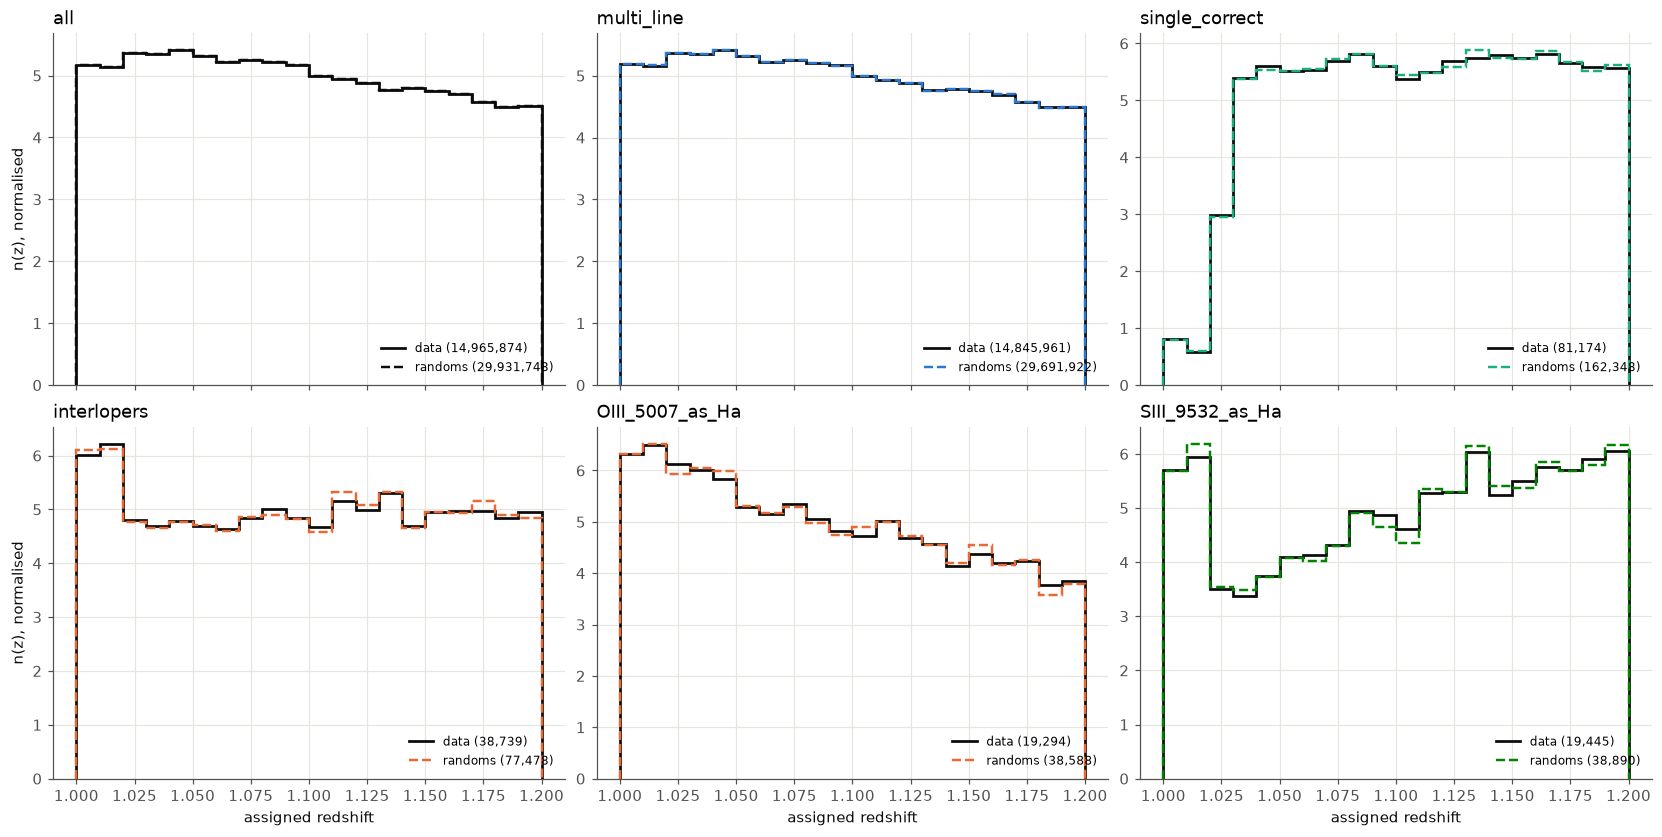

In [4]:
footprint = BaseCatalog(cat.settings["base"]).footprint
edges = np.linspace(1.0, 1.2, 21)
colors = {"all": TEXT_PRIMARY, "multi_line": OUTCOME_COLORS["MULTI_LINE"], "single_correct": OUTCOME_COLORS["SINGLE_CORRECT"],
          "interlopers": OUTCOME_COLORS["SINGLE_MISID"]}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True, sharex=True)
print(f"{'which':<18s}{'data':>12s}{'randoms':>14s}{'inside footprint':>18s}{'randoms/data per bin':>24s}")
for ax, (which, path) in zip(axes.flat, files.items()):
    data = cat.subset(which)
    ran = Catalog.read(path)
    inside = footprint.contains(ran["ra"], ran["dec"]).mean()
    n_data = np.histogram(data["redshift_assigned"], edges)[0]
    n_ran = np.histogram(ran["redshift_assigned"], edges)[0] / N_TIMES
    ok = n_data > 0
    ratio = n_ran[ok] / n_data[ok]
    print(f"{which:<18s}{len(data):>12,}{len(ran):>14,}{inside:>18.4f}{ratio.min():>15.3f} - {ratio.max():.3f}")
    color = colors.get(which, feature_color(which.split("_as_")[0]))
    density = lambda n: n / n.sum() / np.diff(edges)
    ax.stairs(density(n_data), edges, color=TEXT_PRIMARY, lw=1.8, label=f"data ({len(data):,})")
    ax.stairs(density(n_ran), edges, color=color, lw=1.6, ls="--", label=f"randoms ({len(ran):,})")
    ax.set_title(which, loc="left")
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8, loc="lower right")
for ax in axes[-1]:
    ax.set_xlabel("assigned redshift")
for ax in axes[:, 0]:
    ax.set_ylabel("n(z), normalised")
plt.show()


Every random point is inside the footprint. The n(z) of each random catalog follows its own data within the
Poisson noise of twice as many points:

* 0.998–1.002 per bin of 0.01 for the whole catalog and the multi-line galaxies (15 M);
* 0.98–1.04 for the 81 k single-line galaxies with a correct redshift and the 39 k interlopers;
* 0.95–1.04 for each kind of interloper (19 k each).

The parts have different n(z), which is why each needs randoms of its own. The single-line galaxies with a correct
redshift are rare below z = 1.025. [O III] taken for Hα falls with the assigned redshift, while [S III] λ9532 taken for
Hα rises.

## Reproducible, extensible, independent

The randoms of a data catalog depend on `(seed, the data)` only. They come in blocks of the size of the data, each from
its own random stream, so more points can be added later without changing the first ones. A part of the catalog has
other data, so its randoms are independent of those of the whole catalog even with the same seed.

In [5]:
part = cat.subset("OIII_5007_as_Ha")
first = Catalog.read(files["OIII_5007_as_Ha"])
again = part.make_random(N_TIMES, seed=SEED, verbose=False)           # in memory, not written
more = part.make_random(N_TIMES + 3, seed=SEED, verbose=False)
other = cat.subset("SIII_9532_as_Ha").make_random(1, seed=SEED, verbose=False)
print("the same data, made again:          ", np.array_equal(again["ra"], first["ra"]))
print("more points keep the first ones:    ", np.array_equal(more["ra"][:len(first)], first["ra"]))
print("another part, independent points:   ", not np.array_equal(other["ra"][:1000], first["ra"][:1000]))
print(first.settings["random"])


the same data, made again:           True
more points keep the first ones:     True
another part, independent points:    True
{'n_times': 2, 'n_data': 19294, 'seed': 2026, 'data_key': 8590012593047943306}


## Using them, and other ways to make them

The files are plain HDF5 with the datasets `ra`, `dec` and `redshift_assigned`:

```python
data = Catalog.read(CATALOG).subset("OIII_5007_as_Ha")
randoms = Catalog.read(files["OIII_5007_as_Ha"])
data["ra"], data["dec"], data["redshift_assigned"]              # numpy arrays
```

Step 2 of a catalog can write the randoms of the whole catalog with it:

```python
proposal.make_catalog(confusion, out_dir, n_randoms=10)        # out_dir/<name>_random.hdf5
```

From the command line, for the whole catalog or for one part of it:

```bash
romanmock random $PSCRATCH/RomanMocks/examples/Ha_z1p0_1p2_empirical/Ha_z1p0_1p2.hdf5 -n 10 --seed 2026
romanmock random $PSCRATCH/RomanMocks/examples/Ha_z1p0_1p2_empirical/Ha_z1p0_1p2.hdf5 -n 10 --subset OIII_5007_as_Ha
```

Notes:

* The redshifts of the randoms are drawn from the data. That carries the radial structure of the data into the randoms
  and slightly suppresses the clustering of the modes along the line of sight.
* The randoms of `"all"` are not the sum of those of the parts: each is drawn from its own data.
* A cut on `ra` or `dec` made with `cuts=` in `make_catalog` applies to the randoms as well.